# Chapter 3 – Classification: Exercises

| # | Exercise | Expected result |
|---|---|---|
| 1 | MNIST classifier with 97%+ accuracy (KNN + grid search) | ~97.1% |
| 2 | Data augmentation (shift images by 1 pixel) | ~97.6%, error rate down ~17% |
| 3 | Titanic survival classifier | SVC ~82.5%, Random Forest ~81.4% (cross-val) |
| 4 | Spam classifier | ~98.5% cross-val, high precision and recall |

**Run the Setup cell first.** Exercises 1 and 2 are slow (KNN on 60,000 images).

## Setup

In [1]:
# Install the extra libraries used in Exercise 4 (only needed once)
%pip install -q nltk urlextract

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
%pip install -U scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# WHAT: Import everything the exercises need.
import sys
import re
import tarfile
import urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import precision_score, recall_score

np.random.seed(42)

In [7]:
# WHAT: Load MNIST (70,000 images of handwritten digits, 28x28 pixels = 784 numbers each).
# The first download takes a minute; after that it is cached.
# MNIST is already split: first 60,000 = training, last 10,000 = test.
mnist = fetch_openml('mnist_784', as_frame=False, parser="liac-arff")
X, y = mnist.data, mnist.target
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]
X_train.shape, X_test.shape   # (60000, 784), (10000, 784)

((60000, 784), (10000, 784))

## Exercise 1 – MNIST classifier with over 97% accuracy
Hint from the book: use `KNeighborsClassifier` and grid search `weights` and `n_neighbors`.

In [8]:
# BASELINE: KNN with default settings (n_neighbors=5, weights="uniform").
# KNN looks at the K most similar training images and votes on the digit.
# WARNING: score() on 10,000 test images takes a few minutes.
knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train, y_train)
baseline_accuracy = knn_clf.score(X_test, y_test)
baseline_accuracy   # book: 0.9688 – already close to 97%

0.9688

In [9]:
# GRID SEARCH: try 2 weights x 4 neighbor counts = 8 combinations, 5-fold CV.
# Only the first 10,000 images, so it finishes in reasonable time.
#   weights="distance" -> closer neighbors get a bigger vote
param_grid = [{'weights': ["uniform", "distance"], 'n_neighbors': [3, 4, 5, 6]}]

knn_clf = KNeighborsClassifier()
grid_search = GridSearchCV(knn_clf, param_grid, cv=5)
grid_search.fit(X_train[:10_000], y_train[:10_000])

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'n_neighbors': [3, 4, ...], 'weights': ['uniform', 'distance']}]"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information 

In [10]:
grid_search.best_params_   # book: {'n_neighbors': 4, 'weights': 'distance'}

{'n_neighbors': 4, 'weights': 'distance'}

In [11]:
grid_search.best_score_    # book: ~0.944 (lower only because we used 10,000 images)

np.float64(0.9441999999999998)

In [12]:
# Re-train the best model on ALL 60,000 images, then test it.
grid_search.best_estimator_.fit(X_train, y_train)
tuned_accuracy = grid_search.score(X_test, y_test)
tuned_accuracy   # book: 0.9714 -> goal reached!

0.9714

## Exercise 2 – Data augmentation
Make 4 shifted copies of every training image (left, right, up, down by 1 pixel), train on the bigger set, and check if accuracy improves.

In [13]:
# FUNCTION shift_image(image, dx, dy)
# Input: one image as 784 numbers, dx = pixels right (+) / left (-), dy = down (+) / up (-)
# Output: the shifted image as 784 numbers. Empty space is filled with 0 (white).
from scipy.ndimage import shift

def shift_image(image, dx, dy):
    image = image.reshape((28, 28))                          # 784 -> 28x28 grid
    shifted_image = shift(image, [dy, dx], cval=0, mode="constant")
    return shifted_image.reshape([-1])                       # back to 784

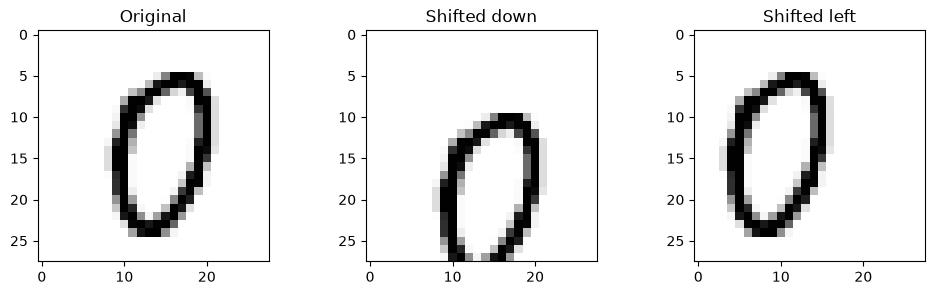

In [14]:
# Test: show one digit, shifted down 5 and left 5 (big shifts so you can see them)
image = X_train[1000]
shifted_image_down = shift_image(image, 0, 5)
shifted_image_left = shift_image(image, -5, 0)

plt.figure(figsize=(12, 3))
for i, (img, title) in enumerate([(image, "Original"),
                                  (shifted_image_down, "Shifted down"),
                                  (shifted_image_left, "Shifted left")]):
    plt.subplot(1, 3, i + 1)
    plt.title(title)
    plt.imshow(img.reshape(28, 28), interpolation="nearest", cmap="Greys")
plt.show()

In [15]:
# Build the augmented training set: originals + 4 shifted copies = 300,000 images.
X_train_augmented = [image for image in X_train]
y_train_augmented = [label for label in y_train]

for dx, dy in ((-1, 0), (1, 0), (0, 1), (0, -1)):      # left, right, down, up
    for image, label in zip(X_train, y_train):
        X_train_augmented.append(shift_image(image, dx, dy))
        y_train_augmented.append(label)                # the digit does not change

X_train_augmented = np.array(X_train_augmented)
y_train_augmented = np.array(y_train_augmented)

# Shuffle so the shifted copies are not all grouped together
shuffle_idx = np.random.permutation(len(X_train_augmented))
X_train_augmented = X_train_augmented[shuffle_idx]
y_train_augmented = y_train_augmented[shuffle_idx]
X_train_augmented.shape   # (300000, 784)

(300000, 784)

In [16]:
# Train the best KNN from Exercise 1 on the augmented data.
# ** unpacks the dict: KNeighborsClassifier(n_neighbors=4, weights='distance')
knn_clf = KNeighborsClassifier(**grid_search.best_params_)
knn_clf.fit(X_train_augmented, y_train_augmented)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",4
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'distance'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[<U1](10,)","['0','1','2',...,'7','8','9']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [17]:
# WARNING: slow (5x more training images to compare against).
augmented_accuracy = knn_clf.score(X_test, y_test)
augmented_accuracy   # book: 0.9763

0.9763

In [18]:
# Accuracy went up only ~0.5%, but the ERROR rate dropped a lot:
# errors went from ~2.86% to ~2.37%  ->  about 17% fewer mistakes.
error_rate_change = (1 - augmented_accuracy) / (1 - tuned_accuracy) - 1
print(f"error_rate_change = {error_rate_change:.0%}")

error_rate_change = -17%


## Exercise 3 – Titanic
Predict the `Survived` column (0 = died, 1 = survived) from the other columns.

In [19]:
# FUNCTION load_titanic_data(): download once, return [train_data, test_data]
def load_titanic_data():
    tarball_path = Path("datasets/titanic.tgz")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/titanic.tgz"
        urllib.request.urlretrieve(url, tarball_path)
        with tarfile.open(tarball_path) as titanic_tarball:
            titanic_tarball.extractall(path="datasets", filter="data")
    return [pd.read_csv(Path("datasets/titanic") / filename)
            for filename in ("train.csv", "test.csv")]

train_data, test_data = load_titanic_data()

# Use PassengerId as the row label (it is not a useful feature)
train_data = train_data.set_index("PassengerId")
test_data = test_data.set_index("PassengerId")
train_data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [20]:
# Look for missing values: Age (~19% missing), Cabin (~77% missing), Embarked (2 missing)
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    str    
 3   Sex       891 non-null    str    
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    str    
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    str    
 10  Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 76.7 KB


In [21]:
# Number stats. Only ~38% survived -> close enough to 50/50 that accuracy is a fair metric.
train_data.describe()

,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699113,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526507,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.416700,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [22]:
# Check the categories
for col in ["Survived", "Pclass", "Sex", "Embarked"]:
    print(train_data[col].value_counts(), "\n")

Survived
0    549
1    342
Name: count, dtype: int64 

Pclass
3    491
1    216
2    184
Name: count, dtype: int64 

Sex
male      577
female    314
Name: count, dtype: int64 

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64 



In [23]:
# PREPROCESSING
# Numbers: fill missing with median, then scale
num_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

# Categories: text -> numbers, fill missing with most common, then one-hot
cat_pipeline = Pipeline([
        ("ordinal_encoder", OrdinalEncoder()),
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("cat_encoder", OneHotEncoder(sparse_output=False)),
    ])

# We skip Name, Ticket and Cabin for now (hard to turn into numbers)
num_attribs = ["Age", "SibSp", "Parch", "Fare"]
cat_attribs = ["Pclass", "Sex", "Embarked"]

preprocess_pipeline = ColumnTransformer([
        ("num", num_pipeline, num_attribs),
        ("cat", cat_pipeline, cat_attribs),
    ])

X_train_titanic = preprocess_pipeline.fit_transform(train_data)
y_train_titanic = train_data["Survived"]
X_train_titanic.shape   # (891, 12)

(891, 12)

In [24]:
# MODEL 1: Random Forest, scored with 10-fold cross-validation
forest_clf = RandomForestClassifier(n_estimators=100, random_state=42)
forest_scores = cross_val_score(forest_clf, X_train_titanic, y_train_titanic, cv=10)
forest_scores.mean()   # book: ~0.814

np.float64(0.8137578027465668)

In [25]:
# MODEL 2: Support Vector Classifier
svm_clf = SVC(gamma="auto")
svm_scores = cross_val_score(svm_clf, X_train_titanic, y_train_titanic, cv=10)
svm_scores.mean()   # book: ~0.825 -> a bit better

np.float64(0.8249313358302123)

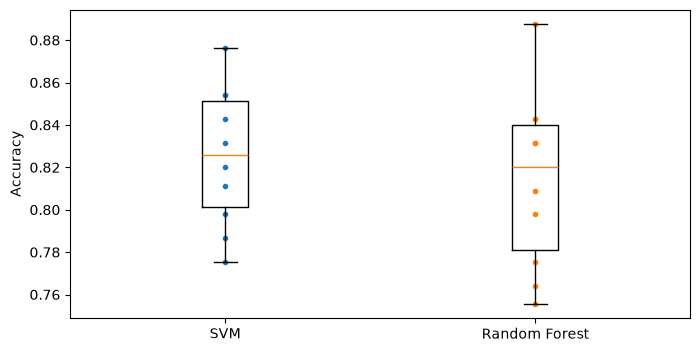

In [26]:
# Compare all 10 fold scores of both models with a box plot.
# SVM: higher average AND smaller spread -> more likely to do well on new data.
plt.figure(figsize=(8, 4))
plt.plot([1]*10, svm_scores, ".")
plt.plot([2]*10, forest_scores, ".")
plt.boxplot([svm_scores, forest_scores])
plt.xticks([1, 2], ["SVM", "Random Forest"])
plt.ylabel("Accuracy")
plt.show()

In [27]:
# Predictions for the test set (no labels given – you could upload these to Kaggle)
svm_clf.fit(X_train_titanic, y_train_titanic)
X_test_titanic = preprocess_pipeline.transform(test_data)
y_pred_titanic = svm_clf.predict(X_test_titanic)
y_pred_titanic[:10]

array([0, 1, 0, 0, 1, 0, 1, 0, 1, 0])

In [28]:
# IDEAS TO IMPROVE (feature engineering):
# Age groups: children (0-15) survived more, 60+ survived less
train_data["AgeBucket"] = train_data["Age"] // 15 * 15
print(train_data[["AgeBucket", "Survived"]].groupby(["AgeBucket"]).mean(), "\n")

# Family size: people alone survived only ~30%
train_data["RelativesOnboard"] = train_data["SibSp"] + train_data["Parch"]
print(train_data[["RelativesOnboard", "Survived"]].groupby(["RelativesOnboard"]).mean())

           Survived
AgeBucket          
0.0        0.576923
15.0       0.362745
30.0       0.423256
45.0       0.404494
60.0       0.240000
75.0       1.000000 

                  Survived
RelativesOnboard          
0                 0.303538
1                 0.552795
2                 0.578431
3                 0.724138
4                 0.200000
5                 0.136364
6                 0.333333
7                 0.000000
10                0.000000


## Exercise 4 – Spam classifier
Turn each email into a vector of word counts, then train a classifier with high precision and recall.

In [29]:
# Download the SpamAssassin emails: 2,500 ham (normal) + 500 spam.
def fetch_spam_data():
    spam_root = "http://spamassassin.apache.org/old/publiccorpus/"
    ham_url = spam_root + "20030228_easy_ham.tar.bz2"
    spam_url = spam_root + "20030228_spam.tar.bz2"

    spam_path = Path() / "datasets" / "spam"
    spam_path.mkdir(parents=True, exist_ok=True)
    for dir_name, tar_name, url in (("easy_ham", "ham", ham_url),
                                    ("spam", "spam", spam_url)):
        if not (spam_path / dir_name).is_dir():
            path = (spam_path / tar_name).with_suffix(".tar.bz2")
            print("Downloading", path)
            urllib.request.urlretrieve(url, path)
            with tarfile.open(path) as tar_bz2_file:
                tar_bz2_file.extractall(path=spam_path, filter="data")
    return [spam_path / dir_name for dir_name in ("easy_ham", "spam")]

ham_dir, spam_dir = fetch_spam_data()

# Each email is one file (skip short-named extra files like "cmds")
ham_filenames = [f for f in sorted(ham_dir.iterdir()) if len(f.name) > 20]
spam_filenames = [f for f in sorted(spam_dir.iterdir()) if len(f.name) > 20]
len(ham_filenames), len(spam_filenames)   # (2500, 500)

(2500, 500)

In [30]:
# Parse each file with Python's email module (handles headers, encodings, attachments)
import email
import email.policy

def load_email(filepath):
    with open(filepath, "rb") as f:
        return email.parser.BytesParser(policy=email.policy.default).parse(f)

ham_emails = [load_email(fp) for fp in ham_filenames]
spam_emails = [load_email(fp) for fp in spam_filenames]

print(spam_emails[6].get_content().strip())

Help wanted.  We are a 14 year old fortune 500 company, that is
growing at a tremendous rate.  We are looking for individuals who
want to work from home.

This is an opportunity to make an excellent income.  No experience
is required.  We will train you.

So if you are looking to be employed from home with a career that has
vast opportunities, then go:

http://www.basetel.com/wealthnow

We are looking for energetic and self motivated people.  If that is you
than click on the link and fill out the form, and one of our
employement specialist will contact you.

To be removed from our link simple go to:

http://www.basetel.com/remove.html


4139vOLW7-758DoDY1425FRhM1-764SMFc8513fCsLl40


In [31]:
# Email STRUCTURE (plain text, HTML, attachments...).
# Function calls itself (recursion) for emails inside emails.
def get_email_structure(email):
    if isinstance(email, str):
        return email
    payload = email.get_payload()
    if isinstance(payload, list):
        multipart = ", ".join([get_email_structure(sub_email)
                               for sub_email in payload])
        return f"multipart({multipart})"
    else:
        return email.get_content_type()

def structures_counter(emails):
    structures = Counter()
    for email in emails:
        structures[get_email_structure(email)] += 1
    return structures

# Finding: ham is mostly plain text; spam often uses HTML.
print(structures_counter(ham_emails).most_common()[:5])
print(structures_counter(spam_emails).most_common()[:5])

[('text/plain', 2408), ('multipart(text/plain, application/pgp-signature)', 66), ('multipart(text/plain, text/html)', 8), ('multipart(text/plain, text/plain)', 4), ('multipart(text/plain)', 3)]
[('text/plain', 218), ('text/html', 183), ('multipart(text/plain, text/html)', 45), ('multipart(text/html)', 20), ('multipart(text/plain)', 19)]


In [32]:
# Split into train and test BEFORE looking more at the data
X_spam = np.array(ham_emails + spam_emails, dtype=object)
y_spam = np.array([0] * len(ham_emails) + [1] * len(spam_emails))   # 0 = ham, 1 = spam

X_train_spam, X_test_spam, y_train_spam, y_test_spam = train_test_split(
    X_spam, y_spam, test_size=0.2, random_state=42)

In [33]:
# FUNCTION html_to_plain_text(html): quick regex way to strip HTML
from html import unescape

def html_to_plain_text(html):
    text = re.sub('<head.*?>.*?</head>', '', html, flags=re.M | re.S | re.I)  # drop <head>
    text = re.sub(r'<a\s.*?>', ' HYPERLINK ', text, flags=re.M | re.S | re.I)  # links -> word
    text = re.sub('<.*?>', '', text, flags=re.M | re.S)                         # remove tags
    text = re.sub(r'(\s*\n)+', '\n', text, flags=re.M | re.S)                # extra newlines
    return unescape(text)                                                     # &gt; -> >

# FUNCTION email_to_text(email): get the text of any email.
# Prefer plain text; if there is only HTML, convert it.
def email_to_text(email):
    html = None
    for part in email.walk():
        ctype = part.get_content_type()
        if not ctype in ("text/plain", "text/html"):
            continue
        try:
            content = part.get_content()
        except:  # encoding problems
            content = str(part.get_payload())
        if ctype == "text/plain":
            return content
        else:
            html = content
    if html:
        return html_to_plain_text(html)

In [34]:
# STEMMING: cut words to their root so "computing", "computed" -> "comput"
import nltk
stemmer = nltk.PorterStemmer()
for word in ("Computations", "Computation", "Computing", "Computed", "Compute"):
    print(word, "=>", stemmer.stem(word))

# URL finder (to replace links with the word "URL")
import urlextract
url_extractor = urlextract.URLExtract()
print(url_extractor.find_urls("Will it detect github.com and https://youtu.be/7Pq-S557XQU?t=3m32s"))

Computations => comput
Computation => comput
Computing => comput
Computed => comput
Compute => comput
['github.com', 'https://youtu.be/7Pq-S557XQU?t=3m32s']


In [35]:
# TRANSFORMER 1: email -> Counter of words, e.g. {"free": 3, "url": 2, ...}
# Each setting can be turned on/off (good for tuning later).
class EmailToWordCounterTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, strip_headers=True, lower_case=True,
                 remove_punctuation=True, replace_urls=True,
                 replace_numbers=True, stemming=True):
        self.strip_headers = strip_headers
        self.lower_case = lower_case
        self.remove_punctuation = remove_punctuation
        self.replace_urls = replace_urls
        self.replace_numbers = replace_numbers
        self.stemming = stemming

    def fit(self, X, y=None):
        return self   # nothing to learn

    def transform(self, X, y=None):
        X_transformed = []
        for email in X:
            text = email_to_text(email) or ""
            if self.lower_case:
                text = text.lower()
            if self.replace_urls and url_extractor is not None:
                urls = list(set(url_extractor.find_urls(text)))
                urls.sort(key=lambda url: len(url), reverse=True)  # longest first
                for url in urls:
                    text = text.replace(url, " URL ")
            if self.replace_numbers:
                text = re.sub(r'\d+(?:\.\d*)?(?:[eE][+-]?\d+)?', 'NUMBER', text)
            if self.remove_punctuation:
                text = re.sub(r'\W+', ' ', text, flags=re.M)
            word_counts = Counter(text.split())
            if self.stemming and stemmer is not None:
                stemmed_word_counts = Counter()
                for word, count in word_counts.items():
                    stemmed_word_counts[stemmer.stem(word)] += count
                word_counts = stemmed_word_counts
            X_transformed.append(word_counts)
        return np.array(X_transformed)

X_few_wordcounts = EmailToWordCounterTransformer().fit_transform(X_train_spam[:3])
X_few_wordcounts

array([Counter({'chuck': 1, 'murcko': 1, 'wrote': 1, 'stuff': 1, 'yawn': 1, 'r': 1}),
       Counter({'the': 11, 'of': 9, 'and': 8, 'all': 3, 'christian': 3, 'to': 3, 'by': 3, 'jefferson': 2, 'i': 2, 'have': 2, 'superstit': 2, 'one': 2, 'on': 2, 'been': 2, 'ha': 2, 'half': 2, 'rogueri': 2, 'teach': 2, 'jesu': 2, 'some': 1, 'interest': 1, 'quot': 1, 'url': 1, 'thoma': 1, 'examin': 1, 'known': 1, 'word': 1, 'do': 1, 'not': 1, 'find': 1, 'in': 1, 'our': 1, 'particular': 1, 'redeem': 1, 'featur': 1, 'they': 1, 'are': 1, 'alik': 1, 'found': 1, 'fabl': 1, 'mytholog': 1, 'million': 1, 'innoc': 1, 'men': 1, 'women': 1, 'children': 1, 'sinc': 1, 'introduct': 1, 'burnt': 1, 'tortur': 1, 'fine': 1, 'imprison': 1, 'what': 1, 'effect': 1, 'thi': 1, 'coercion': 1, 'make': 1, 'world': 1, 'fool': 1, 'other': 1, 'hypocrit': 1, 'support': 1, 'error': 1, 'over': 1, 'earth': 1, 'six': 1, 'histor': 1, 'american': 1, 'john': 1, 'e': 1, 'remsburg': 1, 'letter': 1, 'william': 1, 'short': 1, 'again': 1, 'becom

In [36]:
# TRANSFORMER 2: word counts -> sparse vector.
# fit(): build a vocabulary of the most common words (word -> column number).
# transform(): column 0 = count of words NOT in the vocabulary,
#              column i = count of vocabulary word i.
from scipy.sparse import csr_matrix

class WordCounterToVectorTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, vocabulary_size=1000):
        self.vocabulary_size = vocabulary_size

    def fit(self, X, y=None):
        total_count = Counter()
        for word_count in X:
            for word, count in word_count.items():
                total_count[word] += min(count, 10)   # cap so one long email can't dominate
        most_common = total_count.most_common()[:self.vocabulary_size]
        self.vocabulary_ = {word: index + 1
                            for index, (word, count) in enumerate(most_common)}
        return self

    def transform(self, X, y=None):
        rows, cols, data = [], [], []
        for row, word_count in enumerate(X):
            for word, count in word_count.items():
                rows.append(row)
                cols.append(self.vocabulary_.get(word, 0))   # 0 = unknown word
                data.append(count)
        return csr_matrix((data, (rows, cols)),
                          shape=(len(X), self.vocabulary_size + 1))

vocab_transformer = WordCounterToVectorTransformer(vocabulary_size=10)
X_few_vectors = vocab_transformer.fit_transform(X_few_wordcounts)
print(X_few_vectors.toarray())
vocab_transformer.vocabulary_

[[ 6  0  0  0  0  0  0  0  0  0  0]
 [99 11  9  8  3  1  3  1  3  2  3]
 [67  0  1  2  3  4  1  2  0  1  0]]


{'the': 1,
 'of': 2,
 'and': 3,
 'to': 4,
 'url': 5,
 'all': 6,
 'in': 7,
 'christian': 8,
 'on': 9,
 'by': 10}

In [37]:
# Full pipeline: email -> word counts -> vector, then Logistic Regression.
spam_pipeline = Pipeline([
    ("email_to_wordcount", EmailToWordCounterTransformer()),
    ("wordcount_to_vector", WordCounterToVectorTransformer()),
])

X_train_transformed = spam_pipeline.fit_transform(X_train_spam)

log_clf = LogisticRegression(max_iter=1000, random_state=42)
score = cross_val_score(log_clf, X_train_transformed, y_train_spam, cv=3)
score.mean()   # book: ~0.985

np.float64(0.985)

In [38]:
# Final check on the test set.
# Precision = of emails marked spam, how many really were spam
# Recall    = of all real spam, how many we caught
X_test_transformed = spam_pipeline.transform(X_test_spam)

log_clf = LogisticRegression(max_iter=1000, random_state=42)
log_clf.fit(X_train_transformed, y_train_spam)
y_pred_spam = log_clf.predict(X_test_transformed)

print(f"Precision: {precision_score(y_test_spam, y_pred_spam):.2%}")
print(f"Recall: {recall_score(y_test_spam, y_pred_spam):.2%}")

Precision: 96.88%
Recall: 97.89%
